In [2]:
print("Hello World") 


Hello World


In [3]:
pip install numpy pandas matplotlib seaborn scikit-learn jupyter

  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 2.1 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 2.8 MB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 3.3 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 4.2 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 5.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 5.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 5.4 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━

In [35]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import r2_score, mean_squared_error


In [47]:
#Load the dataset 

df = pd.read_csv("uber.csv") 

df.head()

# print(df.info())


# print(df.describe())

# print(df.shape)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [37]:

print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [38]:
df.shape

(200000, 9)

In [39]:
df.dtypes

Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [40]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [48]:

#Drop uncessary columns

df.drop(columns=['Unnamed: 0', 'key'], inplace=True)





/var/folders/zs/vfn5k789363gmxvqm3wzwttw0000gn/T/ipykernel_5298/2250465131.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Unnamed: 0', 'key'], inplace=True)


In [45]:
#convert pickup_datetime into datetime

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'] , errors='coerce' , utc=True) 

In [46]:
df['pickup_datetime'].dtypes

datetime64[us, UTC]

In [49]:
df.dropna(inplace=True)

/var/folders/zs/vfn5k789363gmxvqm3wzwttw0000gn/T/ipykernel_5298/1379821321.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [51]:
df.shape

(199999, 7)

In [52]:
df = df[df['fare_amount'] >= 0] 

In [54]:
df.shape

(199982, 7)

In [55]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,199982.000000,199982.000000,199982.000000,199982.000000,199982.000000,199982.000000
mean,11.362302,-72.527508,39.935812,-72.525538,39.924024,1.684502
std,9.897102,11.438294,7.720883,13.116956,6.794527,1.385977
min,0.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734795,-73.991407,40.733824,1.000000
50%,8.500000,-73.981823,40.752592,-73.980092,40.753042,1.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [56]:
df = df[
    (df['pickup_latitude'].between(-90,90)) &
    (df['dropoff_latitude'].between(-90,90)) &
    (df['pickup_longitude'].between(-180,180)) &
    (df['dropoff_longitude'].between(-180,180)) 
]

In [57]:
df = df[df['passenger_count'].between(1,6)]

In [58]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,199261.000000,199261.000000,199261.000000,199261.000000,199261.000000,199261.000000
mean,11.369090,-72.503837,39.918989,-72.513700,39.923096,1.689453
std,9.906025,10.443377,6.128334,10.405451,6.115539,1.305393
min,0.000000,-93.824668,-74.015515,-75.458979,-74.015750,1.000000
25%,6.000000,-73.992063,40.734795,-73.991409,40.733827,1.000000
50%,8.500000,-73.981823,40.752583,-73.980094,40.753042,1.000000
75%,12.500000,-73.967160,40.767155,-73.963662,40.767995,2.000000
max,499.000000,40.808425,48.018760,40.831932,45.031598,6.000000


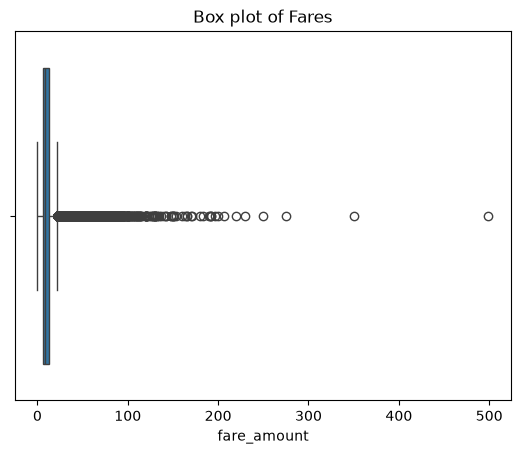

In [59]:
sns.boxplot(x=df['fare_amount'] )
plt.title("Box plot of Fares")
plt.show()

In [61]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)


IQR = Q3 - Q1 


lower = Q1 - 1.5*IQR 
upper = Q3 + 1.5*IQR 

print("Before : " , df.shape)
df = df[(df['fare_amount'] >= lower) &( df['fare_amount'] <= upper)]
print("After : " , df.shape) 

Before :  (199261, 7)
After :  (182141, 7)


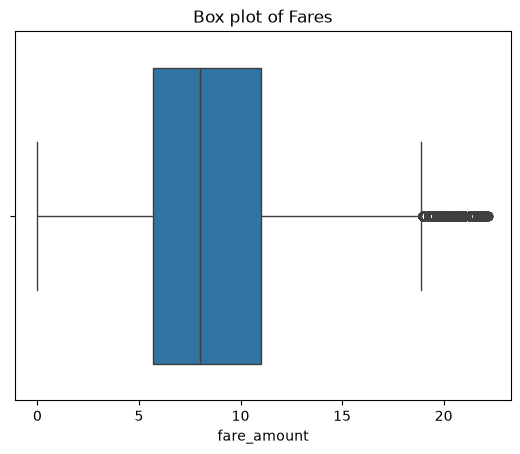

In [62]:
sns.boxplot(x=df['fare_amount'] )
plt.title("Box plot of Fares")
plt.show()

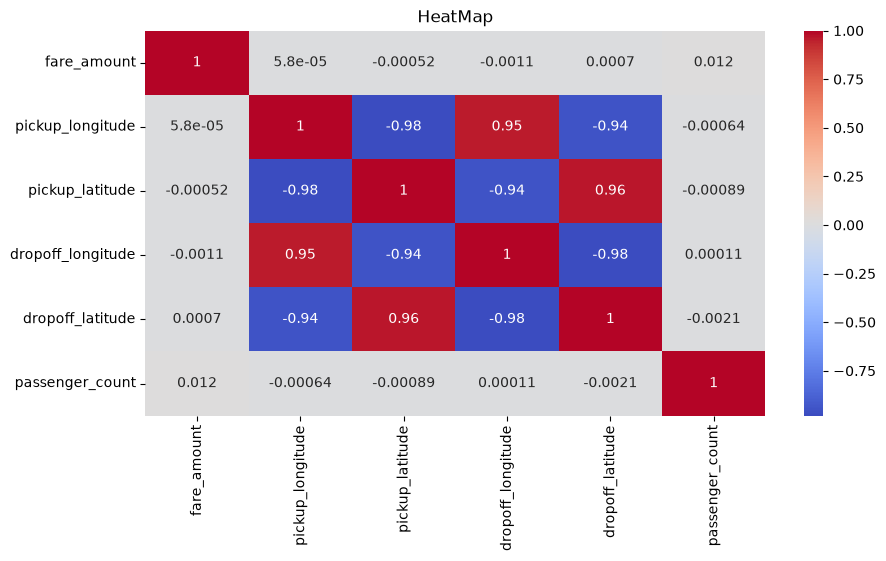

In [64]:
plt.figure(figsize=(10,5)) 

sns.heatmap(df.select_dtypes(include='number').corr() , annot=True , cmap='coolwarm')

plt.title("HeatMap")

plt.show()

In [ ]:
from math import radians, sin , cos , asin , sqrt


def distance(lat1 , lat2 , long1 , long2) : 
    lat1 , lat2 , long1 , long2 = map(radians , [lat1 , lat2 , long1 , long2]) 


    dlat = lat2-lat1 
   # dlong = long2 - long2 
    dlong = long2 - long1

    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlong/2)**2 

    return 2*6371*asin(sqrt(a))



df['distance'] = df.apply(
    lambda row:distance(
        row['pickup_latitude'] ,
        row['dropoff_latitude'] , 
        row['pickup_longitude'] , 
        row['dropoff_longitude']
    ) , axis = 1 
)


df.head() 





,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,1.683126
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,2.457408
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,3.544561
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,1.390493
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,1.908327


In [69]:
X = df[['distance' , 'passenger_count']] 
y = df['fare_amount'] 


In [75]:
X_train , X_test , y_train , y_test = train_test_split(
    X , y , test_size=0.2 , random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (145712, 2)
Testing Data: (36429, 2)


In [76]:
lr = LinearRegression() 

lr.fit(X_train , y_train) 


y_preds = lr.predict(X_test) 

In [77]:
r2_lr = r2_score(y_test , y_preds)

rmse_lr = np.sqrt(mean_squared_error(y_test , y_preds)) 

print("Linear Regression Results")

print("R2 Score:", r2_lr)

print("RMSE:", rmse_lr)

Linear Regression Results
R2 Score: 0.00033882389855821593
RMSE: 4.149286354494063


In [82]:
rf = RandomForestRegressor(n_estimators=100 , random_state=42) 

rf.fit(X_train , y_train) 

y_pred2 = rf.predict(X_test)

In [83]:
rf_lr = r2_score(y_test , y_pred2) 

rmse_rf = np.sqrt(mean_squared_error(y_test , y_pred2)) 


print("Random Foresr Regression Results")

print("R2 Score:", rf_lr)

print("RMSE:", rmse_rf)


Random Foresr Regression Results
R2 Score: 0.3692163727505342
RMSE: 3.2959999848711683


In [84]:
# Create comparison dataframe
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest Regression'
    ],

    'R2 Score': [
        r2_lr,
        rf_lr
    ],

    'RMSE': [
        rmse_lr,
        rmse_rf
    ]
})

print(results)

# Find best model
best_model = results.loc[
    results['R2 Score'].idxmax()
]

print("\nBest Model:", best_model['Model'])

                      Model  R2 Score      RMSE
0         Linear Regression  0.000339  4.149286
1  Random Forest Regression  0.369216  3.296000

Best Model: Random Forest Regression


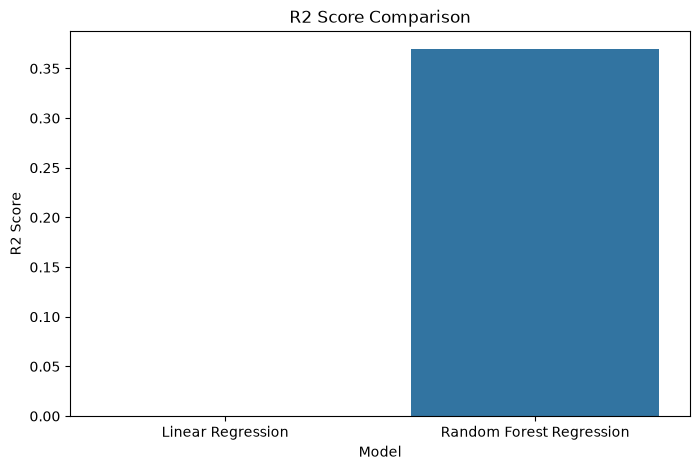

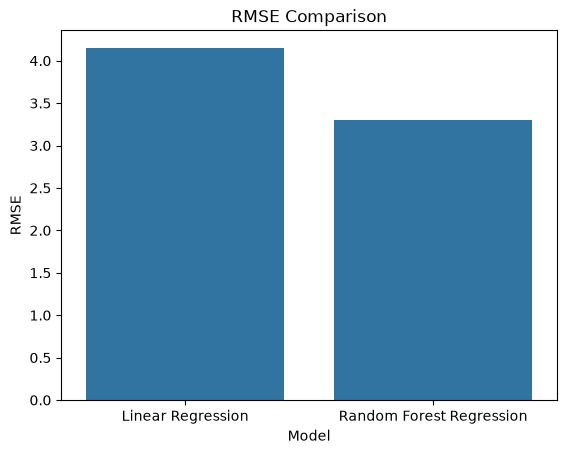

In [85]:
plt.figure(figsize=(8,5)) 

sns.barplot(
    x='Model' ,
    y='R2 Score' ,
    data=results
)


plt.title("R2 Score Comparison")

plt.show()

sns.barplot(
    x='Model',
    y='RMSE',
    data=results
)

plt.title("RMSE Comparison")

plt.show()

In [88]:
new_ride = pd.DataFrame( {'distance' : [5.0] 
                          , 'passenger_count' : [2]
                          })

prediction = rf.predict(new_ride) 

print("Preficted Uber ride : $" , prediction[0]) 

Preficted Uber ride : $ 14.916000000000004
